# Gender Detection System

This notebook classifies face images as **Male** or **Female** with a neural network built in TensorFlow/Keras.

**Pipeline:** load the images → convert to grayscale and resize to 128×128 → flatten and L2-normalise → train a dense neural network → evaluate it on a held-out test set.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import shuffle
from tensorflow import keras

from src.gender_detection import (CLASS_NAMES, DATA_DIR, IMG_SIZE, MODEL_PATH,
                                  load_split, predict_image, preprocess)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

SCREENSHOTS = Path("screenshots")
SCREENSHOTS.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Load the dataset
Images are stored as `train/`, `valid/` and `test/` folders, each with `men/` and `women/` sub-folders. Labels: **women = 0**, **men = 1**.

In [2]:
x_train, y_train = load_split("train")
x_valid, y_valid = load_split("valid")
x_test, y_test = load_split("test")

for name, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]:
    print(f"{name:>5}: {len(y):4d} images  (female={np.sum(y == 0)}, male={np.sum(y == 1)})")
print("Image shape:", x_train.shape[1:])

train: 1599 images  (female=799, male=800)
valid:  340 images  (female=170, male=170)
 test:  340 images  (female=170, male=170)
Image shape: (128, 128)


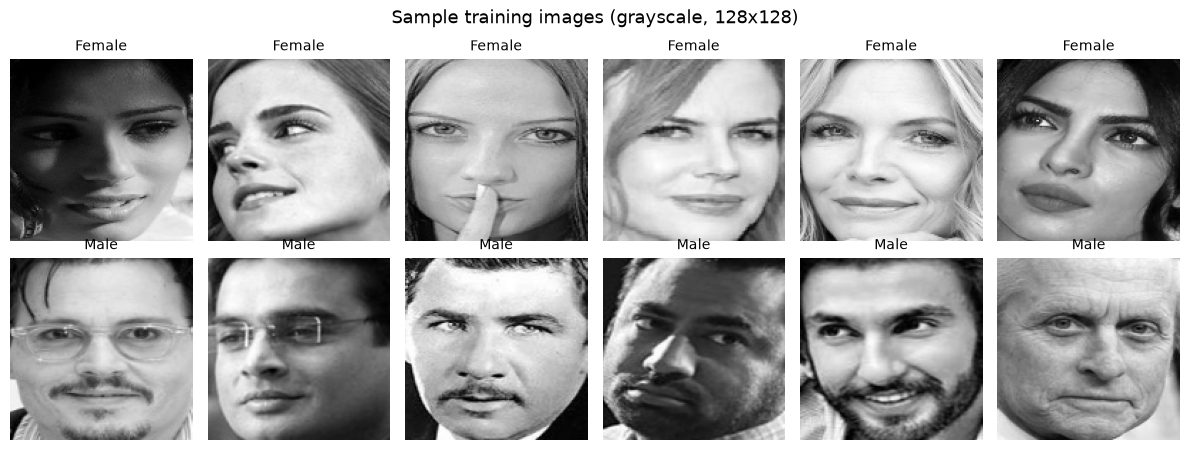

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for row, label in enumerate([0, 1]):
    idx = np.random.choice(np.where(y_train == label)[0], 6, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(x_train[i], cmap="gray")
        ax.set_title(CLASS_NAMES[label], fontsize=10)
        ax.axis("off")
fig.suptitle("Sample training images (grayscale, 128x128)", fontsize=13)
plt.tight_layout()
plt.savefig(SCREENSHOTS / "sample_faces.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Preprocess
Each 128×128 image is flattened into a 16,384-value vector and L2-normalised. The same `preprocess()` function is used later for single-image predictions, so training and inference stay consistent.

In [4]:
X_train, X_valid, X_test = preprocess(x_train), preprocess(x_valid), preprocess(x_test)
X_train, y_train_s = shuffle(X_train, y_train, random_state=SEED)
X_valid, y_valid_s = shuffle(X_valid, y_valid, random_state=SEED)

Y_train = keras.utils.to_categorical(y_train_s, 2)
Y_valid = keras.utils.to_categorical(y_valid_s, 2)
Y_test = keras.utils.to_categorical(y_test, 2)
print(X_train.shape, Y_train.shape)

(1599, 16384) (1599, 2)


## 3. Build the model
Two hidden dense layers with ReLU, each followed by 50% dropout to reduce overfitting, and a 2-unit sigmoid output.

In [5]:
model = keras.Sequential([
    keras.Input(shape=(IMG_SIZE * IMG_SIZE,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(2, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057,218 (4.03 MB)

 Trainable params: 1,057,218 (4.03 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train

In [6]:
history = model.fit(X_train, Y_train, epochs=30, batch_size=32,
                    validation_data=(X_valid, Y_valid), verbose=2)

Epoch 1/30


50/50 - 4s - 80ms/step - accuracy: 0.5572 - loss: 0.6850 - val_accuracy: 0.6618 - val_loss: 0.6559


Epoch 2/30


50/50 - 1s - 23ms/step - accuracy: 0.6735 - loss: 0.6334 - val_accuracy: 0.7206 - val_loss: 0.5866


Epoch 3/30


...

50/50 - 1s - 26ms/step - accuracy: 0.8174 - loss: 0.3774 - val_accuracy: 0.7559 - val_loss: 0.4719


Epoch 29/30


50/50 - 1s - 21ms/step - accuracy: 0.8024 - loss: 0.3937 - val_accuracy: 0.8000 - val_loss: 0.4041


Epoch 30/30


50/50 - 1s - 19ms/step - accuracy: 0.8011 - loss: 0.3839 - val_accuracy: 0.7794 - val_loss: 0.4278


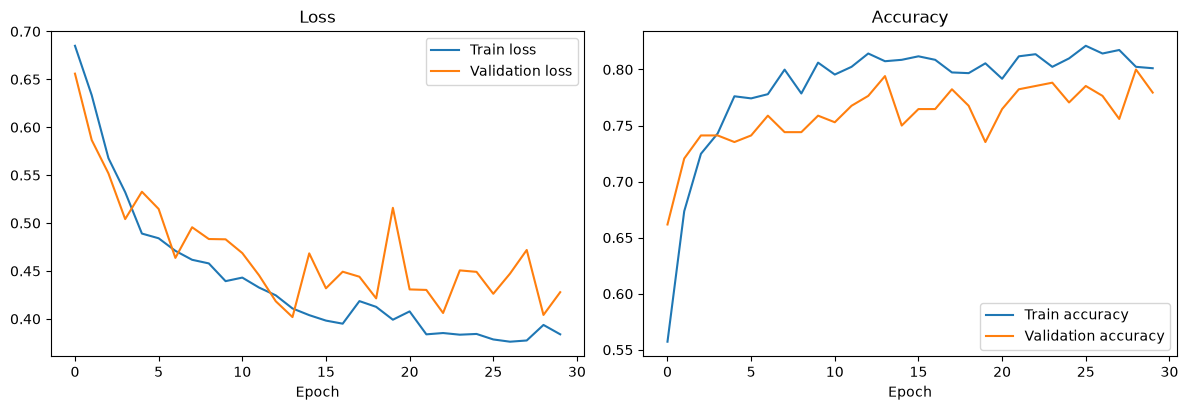

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(history.history["loss"], label="Train loss")
ax1.plot(history.history["val_loss"], label="Validation loss")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()
ax2.plot(history.history["accuracy"], label="Train accuracy")
ax2.plot(history.history["val_accuracy"], label="Validation accuracy")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout()
plt.savefig(SCREENSHOTS / "training_curves.png", dpi=110, bbox_inches="tight")
plt.show()

## 5. Evaluate on the test set

In [8]:
test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Test loss:     0.4004
Test accuracy: 0.8206



              precision    recall  f1-score   support

      Female      0.966     0.665     0.787       170
        Male      0.744     0.976     0.845       170

    accuracy                          0.821       340
   macro avg      0.855     0.821     0.816       340
weighted avg      0.855     0.821     0.816       340



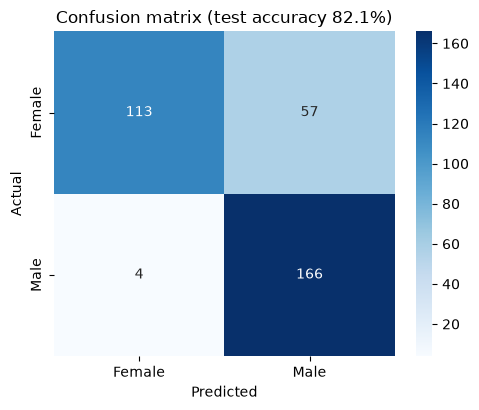

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion matrix (test accuracy {test_acc:.1%})")
plt.tight_layout()
plt.savefig(SCREENSHOTS / "confusion_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

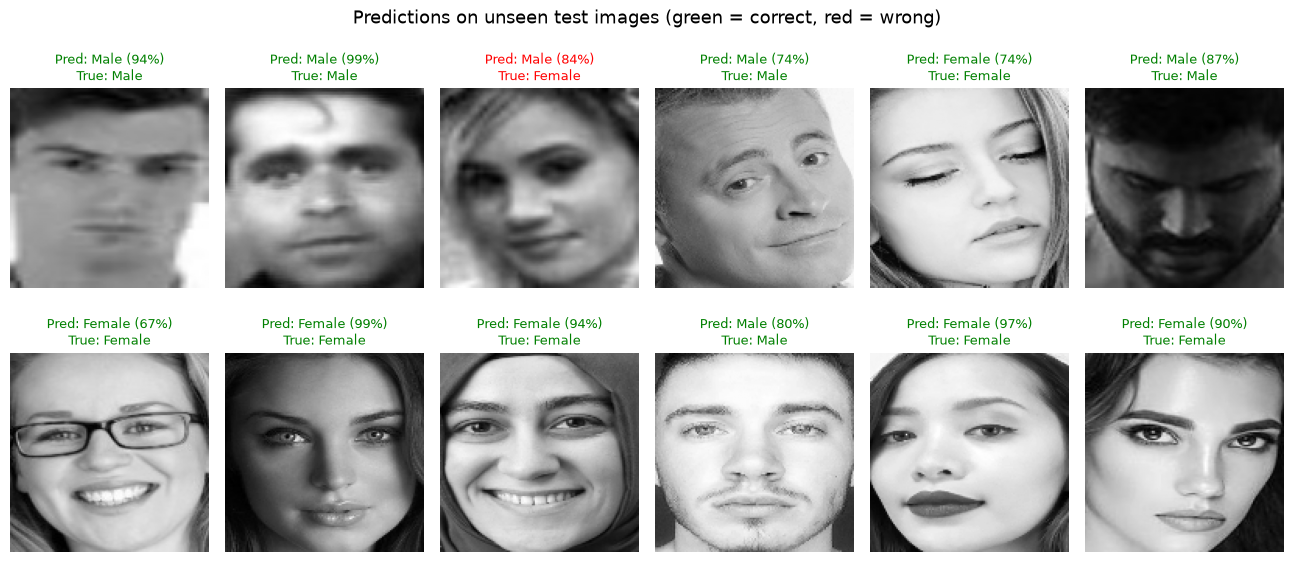

In [10]:
probs = model.predict(X_test, verbose=0)
idx = np.random.choice(len(x_test), 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 5.6))
fig.subplots_adjust(left=0.01, right=0.99, top=0.84, bottom=0.01, wspace=0.08, hspace=0.32)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i], cmap="gray")
    pred, true = y_pred[i], y_test[i]
    ax.set_title(f"Pred: {CLASS_NAMES[pred]} ({probs[i][pred]:.0%})\nTrue: {CLASS_NAMES[true]}",
                 fontsize=9, color="green" if pred == true else "red")
    ax.axis("off")
fig.suptitle("Predictions on unseen test images (green = correct, red = wrong)", fontsize=13)
plt.savefig(SCREENSHOTS / "sample_predictions.png", dpi=110, bbox_inches="tight")
plt.show()

## 6. Save the model and predict a single image

In [11]:
MODEL_PATH.parent.mkdir(exist_ok=True)
model.save(MODEL_PATH)
print("Saved model to", MODEL_PATH.relative_to(Path.cwd()))

sample = sorted((DATA_DIR / "test" / "men").iterdir())[0]
loaded = keras.models.load_model(MODEL_PATH)
label, confidence = predict_image(loaded, sample)
print(f"Prediction for a test image: {label} ({confidence:.1%})")

Saved model to model\gender_model.keras


Prediction for a test image: Male (80.1%)
